In [2]:
import warnings, pickle, time
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV, cross_validate
from sklearn.preprocessing import StandardScaler, LabelEncoder, label_binarize
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             roc_auc_score, roc_curve, auc)
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
import shap

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

## 1. Dataset Loading & Exploration

In [3]:
# Update the path if the CSV is stored elsewhere
DATA_PATH = "random_customer_risk_dataset.csv"
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
df.head()

Shape: (5000, 13)


,Customer_ID,Age,Annual_Income,Credit_Score,Loan_Amount,Employment_Type,Education_Level,Marital_Status,Existing_Loans,Late_Payments,Debt_to_Income,Years_Employed,Risk_Category
0,CUST00001,22,39861,668,16505,Business,High School,Single,1,1,0.311,9.3,Low
1,CUST00002,59,38103,756,29811,Business,Master,Single,1,1,1.264,17.6,Low
2,CUST00003,52,74827,746,31159,Salaried,Bachelor,Married,1,1,0.254,11.1,Low
3,CUST00004,41,76919,651,11771,Salaried,Bachelor,Married,2,0,0.236,1.3,Medium
4,CUST00005,40,36523,451,15256,Salaried,High School,Single,0,0,0.436,14.0,High


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Customer_ID      5000 non-null   str    
 1   Age              5000 non-null   int64  
 2   Annual_Income    5000 non-null   int64  
 3   Credit_Score     5000 non-null   int64  
 4   Loan_Amount      5000 non-null   int64  
 5   Employment_Type  5000 non-null   str    
 6   Education_Level  5000 non-null   str    
 7   Marital_Status   5000 non-null   str    
 8   Existing_Loans   5000 non-null   int64  
 9   Late_Payments    5000 non-null   int64  
 10  Debt_to_Income   5000 non-null   float64
 11  Years_Employed   5000 non-null   float64
 12  Risk_Category    5000 non-null   str    
dtypes: float64(2), int64(6), str(5)
memory usage: 691.4 KB


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,5000.0,43.925200,15.337061,18.000,31.000,44.0000,57.0000,70.0
Annual_Income,5000.0,57461.574400,33938.268895,12000.000,34038.000,48964.5000,71524.0000,250000.0
Credit_Score,5000.0,647.277800,84.421362,350.000,592.000,647.0000,704.0000,850.0
Loan_Amount,5000.0,33693.251000,23669.152491,2149.000,17557.000,26853.0000,42382.5000,150000.0
Existing_Loans,5000.0,1.415200,1.176897,0.000,1.000,1.0000,2.0000,6.0
Late_Payments,5000.0,1.088800,1.037849,0.000,0.000,1.0000,2.0000,6.0
Debt_to_Income,5000.0,0.881796,0.836247,0.018,0.327,0.5995,1.1225,4.0
Years_Employed,5000.0,6.656260,4.511332,0.100,3.400,5.6000,8.9000,31.7


In [6]:
print("Target distribution:")
print(df["Risk_Category"].value_counts())
print("\nCategorical columns:")
for c in ["Employment_Type", "Education_Level", "Marital_Status"]:
    print(f"{c}: {df[c].unique().tolist()}")

Target distribution:
Risk_Category
Low       1700
Medium    1700
High      1600
Name: count, dtype: int64

Categorical columns:
Employment_Type: ['Business', 'Salaried', 'Unemployed', 'Self-employed']
Education_Level: ['High School', 'Master', 'Bachelor', 'PhD']
Marital_Status: ['Single', 'Married', 'Divorced']


## 2. Data Cleaning (Missing & Duplicate Values)

In [7]:
print("Missing values per column:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate Customer_IDs:", df["Customer_ID"].duplicated().sum())

Missing values per column:
Customer_ID        0
Age                0
Annual_Income      0
Credit_Score       0
Loan_Amount        0
Employment_Type    0
Education_Level    0
Marital_Status     0
Existing_Loans     0
Late_Payments      0
Debt_to_Income     0
Years_Employed     0
Risk_Category      0
dtype: int64

Duplicate rows: 0
Duplicate Customer_IDs: 0


In [8]:
# Handle duplicates & missing values (no-ops on a clean file, but kept so the pipeline is reusable)
df = df.drop_duplicates().reset_index(drop=True)

num_cols_raw = df.select_dtypes(include=np.number).columns
cat_cols_raw = df.select_dtypes(include="object").columns.drop("Customer_ID")
df[num_cols_raw] = df[num_cols_raw].fillna(df[num_cols_raw].median())
for c in cat_cols_raw:
    df[c] = df[c].fillna(df[c].mode()[0])

# Customer_ID is an identifier, not a predictive feature
df = df.drop(columns=["Customer_ID"])
print("Shape after cleaning:", df.shape)

Shape after cleaning: (5000, 12)


## 3. Exploratory Data Analysis (EDA)

In [9]:
num_cols = ["Age", "Annual_Income", "Credit_Score", "Loan_Amount", "Existing_Loans",
            "Late_Payments", "Debt_to_Income", "Years_Employed"]
cat_cols = ["Employment_Type", "Education_Level", "Marital_Status"]

print("Mean of numeric features by Risk_Category:")
df.groupby("Risk_Category")[num_cols].mean().round(2)

Mean of numeric features by Risk_Category:


,Age,Annual_Income,Credit_Score,Loan_Amount,Existing_Loans,Late_Payments,Debt_to_Income,Years_Employed
Risk_Category,,,,,,,,
High,43.49,46487.54,579.00,40936.45,1.57,1.27,1.35,6.42
Low,43.56,67334.39,717.48,28626.65,1.26,0.91,0.56,6.95
Medium,44.70,57917.27,641.34,31942.72,1.42,1.10,0.76,6.59


In [10]:
for c in cat_cols:
    print(f"\nRisk distribution by {c} (row %):")
    print((pd.crosstab(df[c], df["Risk_Category"], normalize="index") * 100).round(1))


Risk distribution by Employment_Type (row %):
Risk_Category    High   Low  Medium
Employment_Type                    
Business         29.2  37.6    33.2
Salaried         28.4  37.8    33.8
Self-employed    31.7  33.5    34.8
Unemployed       51.1  14.2    34.7

Risk distribution by Education_Level (row %):
Risk_Category    High   Low  Medium
Education_Level                    
Bachelor         30.4  34.4    35.2
High School      34.2  32.2    33.6
Master           32.1  35.4    32.6
PhD              31.8  35.4    32.8

Risk distribution by Marital_Status (row %):
Risk_Category   High   Low  Medium
Marital_Status                    
Divorced        33.3  36.0    30.6
Married         31.6  33.9    34.5
Single          32.2  33.7    34.2


In [11]:
# Correlation of numeric features with an ordinal version of the target
risk_order = {"Low": 0, "Medium": 1, "High": 2}
corr = df[num_cols].copy()
corr["Risk_Ordinal"] = df["Risk_Category"].map(risk_order)
corr.corr()["Risk_Ordinal"].drop("Risk_Ordinal").sort_values(ascending=False).round(3)

Debt_to_Income    0.382
Loan_Amount       0.210
Late_Payments     0.140
Existing_Loans    0.106
Age              -0.001
Years_Employed   -0.048
Annual_Income    -0.249
Credit_Score     -0.667
Name: Risk_Ordinal, dtype: float64

## 4. Data Visualization

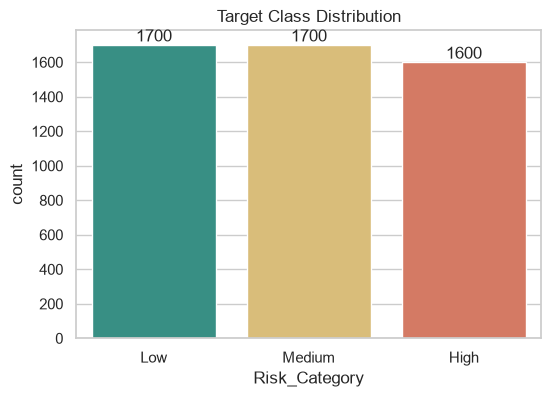

In [12]:
order = ["Low", "Medium", "High"]
palette = {"Low": "#2a9d8f", "Medium": "#e9c46a", "High": "#e76f51"}

fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df, x="Risk_Category", order=order, palette=palette, ax=ax)
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
ax.set_title("Target Class Distribution")
plt.show()

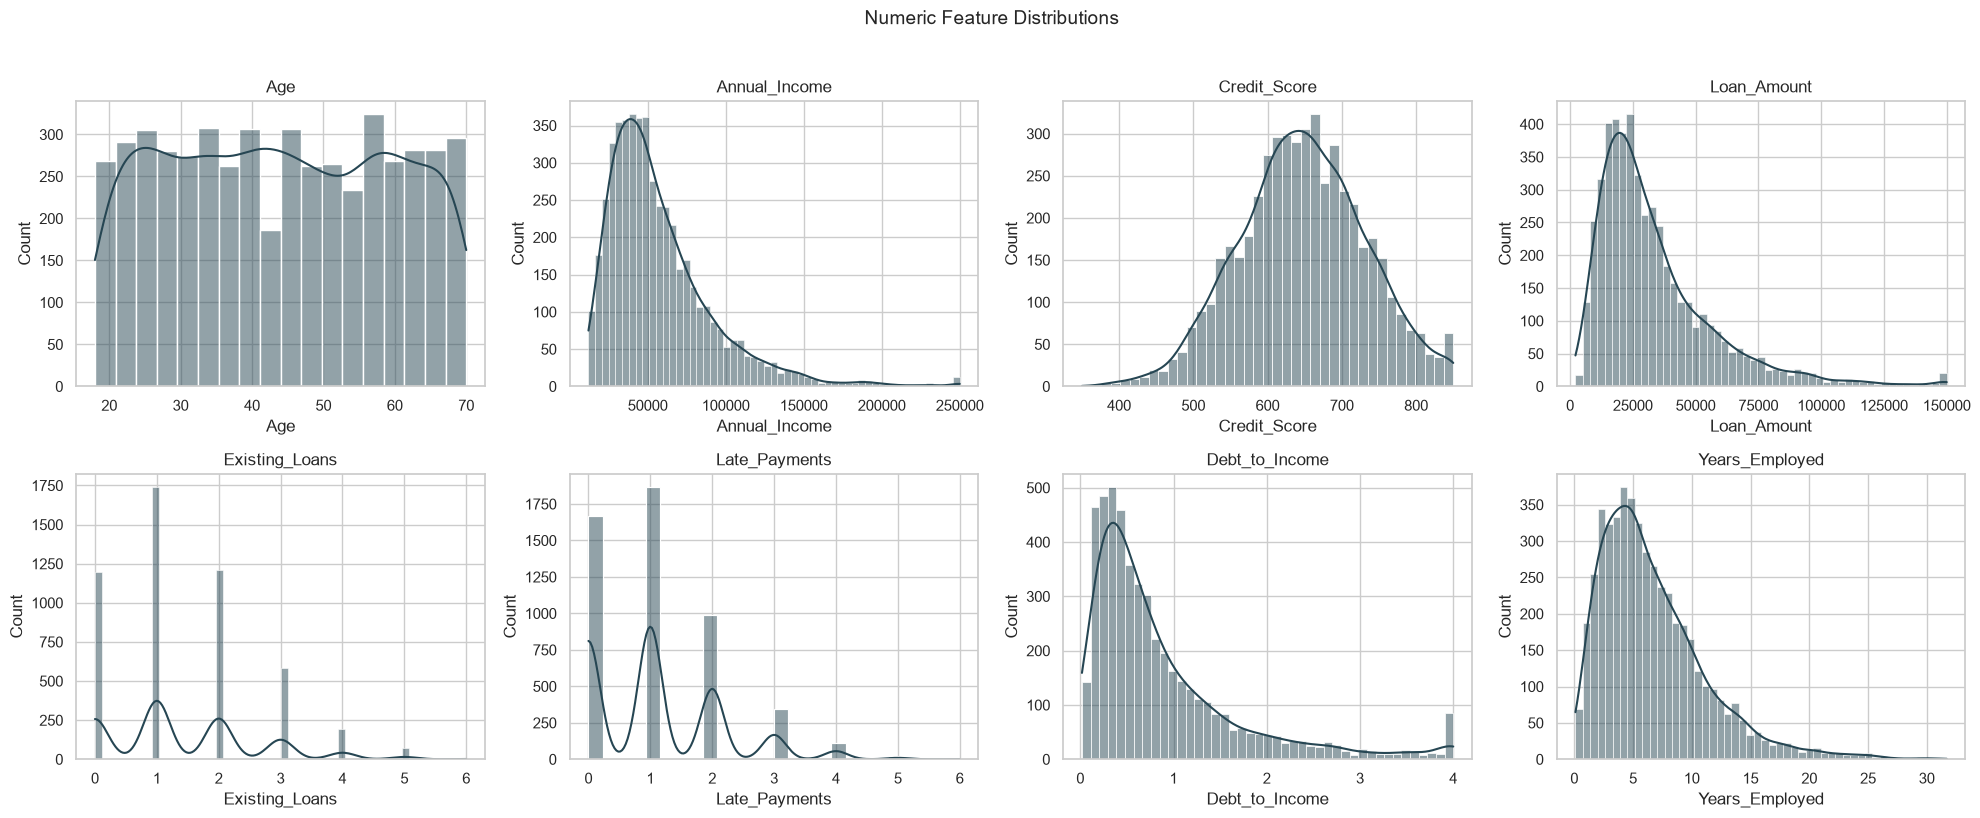

In [13]:
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, c in zip(axes.ravel(), num_cols):
    sns.histplot(df[c], kde=True, ax=ax, color="#264653")
    ax.set_title(c)
plt.suptitle("Numeric Feature Distributions", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

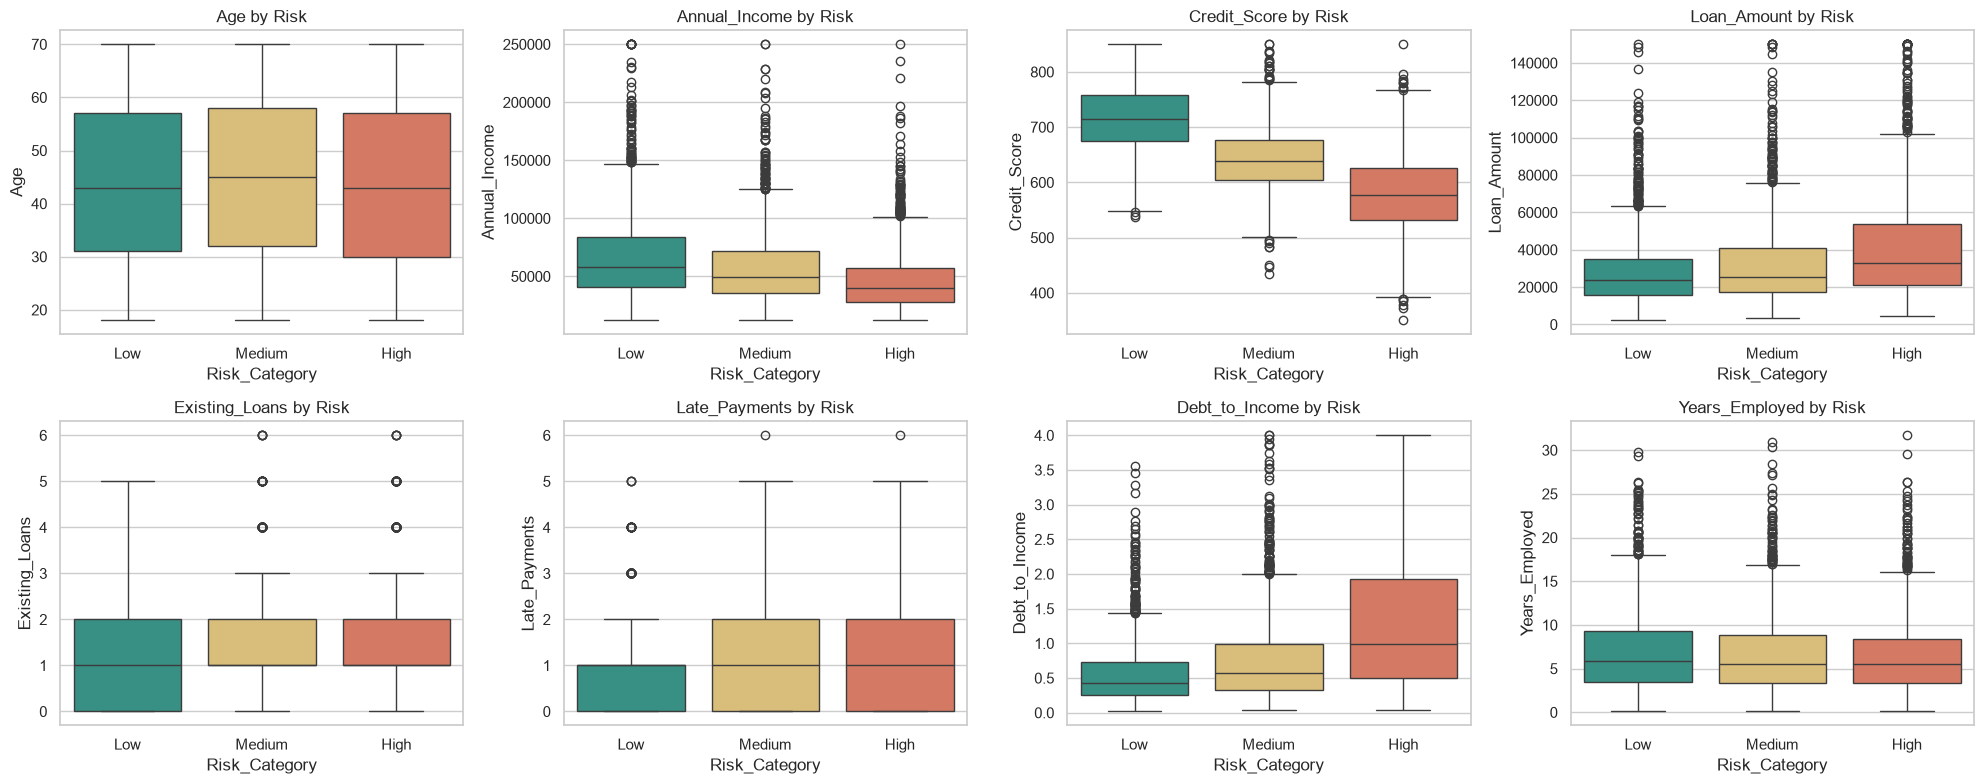

In [14]:
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, c in zip(axes.ravel(), num_cols):
    sns.boxplot(data=df, x="Risk_Category", y=c, order=order, palette=palette, ax=ax)
    ax.set_title(f"{c} by Risk")
plt.tight_layout()
plt.show()

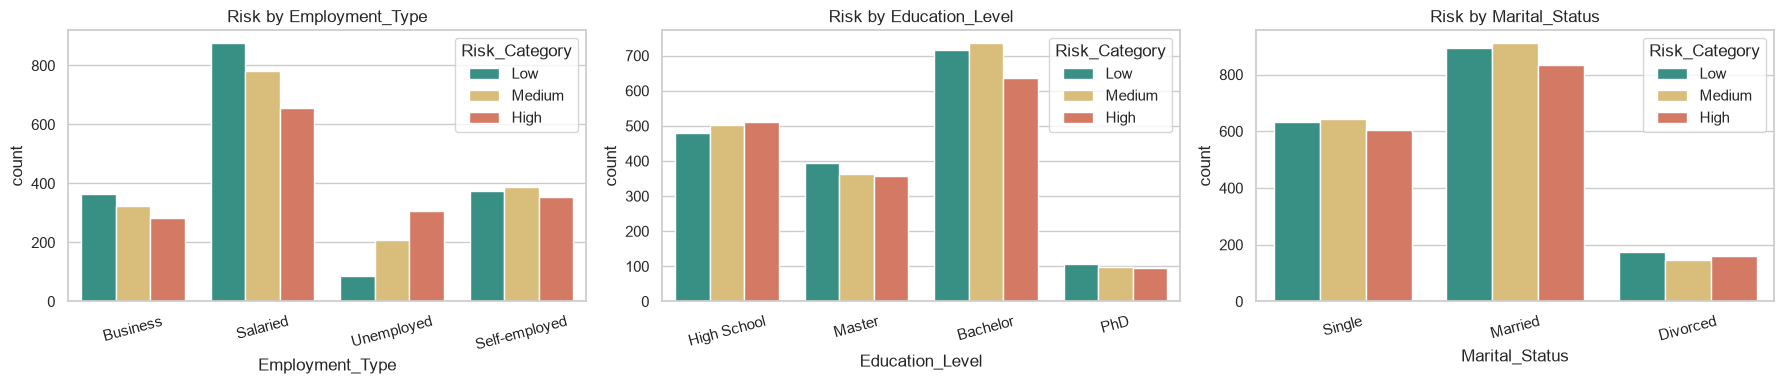

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, c in zip(axes, cat_cols):
    sns.countplot(data=df, x=c, hue="Risk_Category", hue_order=order, palette=palette, ax=ax)
    ax.set_title(f"Risk by {c}")
    ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

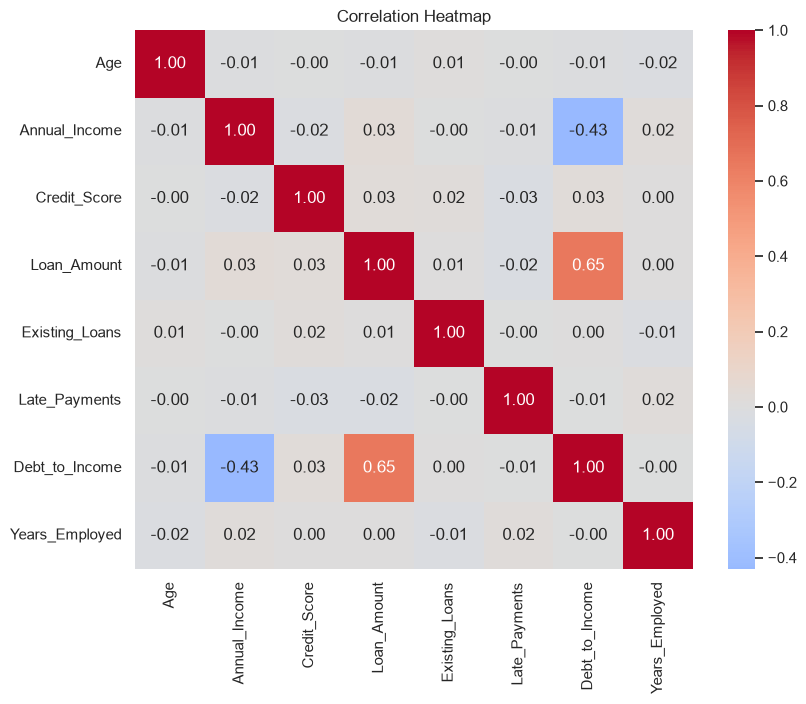

In [16]:
plt.figure(figsize=(9, 7))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.show()

## 5. Outlier Detection & Handling

IQR method to detect outliers, then **winsorization (capping)** at the IQR fences. Capping is preferred over
dropping rows because the dataset is only 5,000 rows and extreme incomes/loans can be genuine, informative customers.

In [17]:
def iqr_bounds(s, k=1.5):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

rows = []
for c in num_cols:
    lo, hi = iqr_bounds(df[c])
    n_out = ((df[c] < lo) | (df[c] > hi)).sum()
    rows.append([c, round(lo, 2), round(hi, 2), n_out, round(100 * n_out / len(df), 2)])
outlier_report = pd.DataFrame(rows, columns=["Feature", "Lower_Fence", "Upper_Fence", "Outliers", "Pct"])
outlier_report

,Feature,Lower_Fence,Upper_Fence,Outliers,Pct
0,Age,-8.00,96.00,0,0.00
1,Annual_Income,-22191.00,127753.00,218,4.36
2,Credit_Score,424.00,872.00,21,0.42
3,Loan_Amount,-19681.25,79620.75,262,5.24
4,Existing_Loans,-0.50,3.50,271,5.42
5,Late_Payments,-3.00,5.00,2,0.04
6,Debt_to_Income,-0.87,2.32,380,7.60
7,Years_Employed,-4.85,17.15,167,3.34


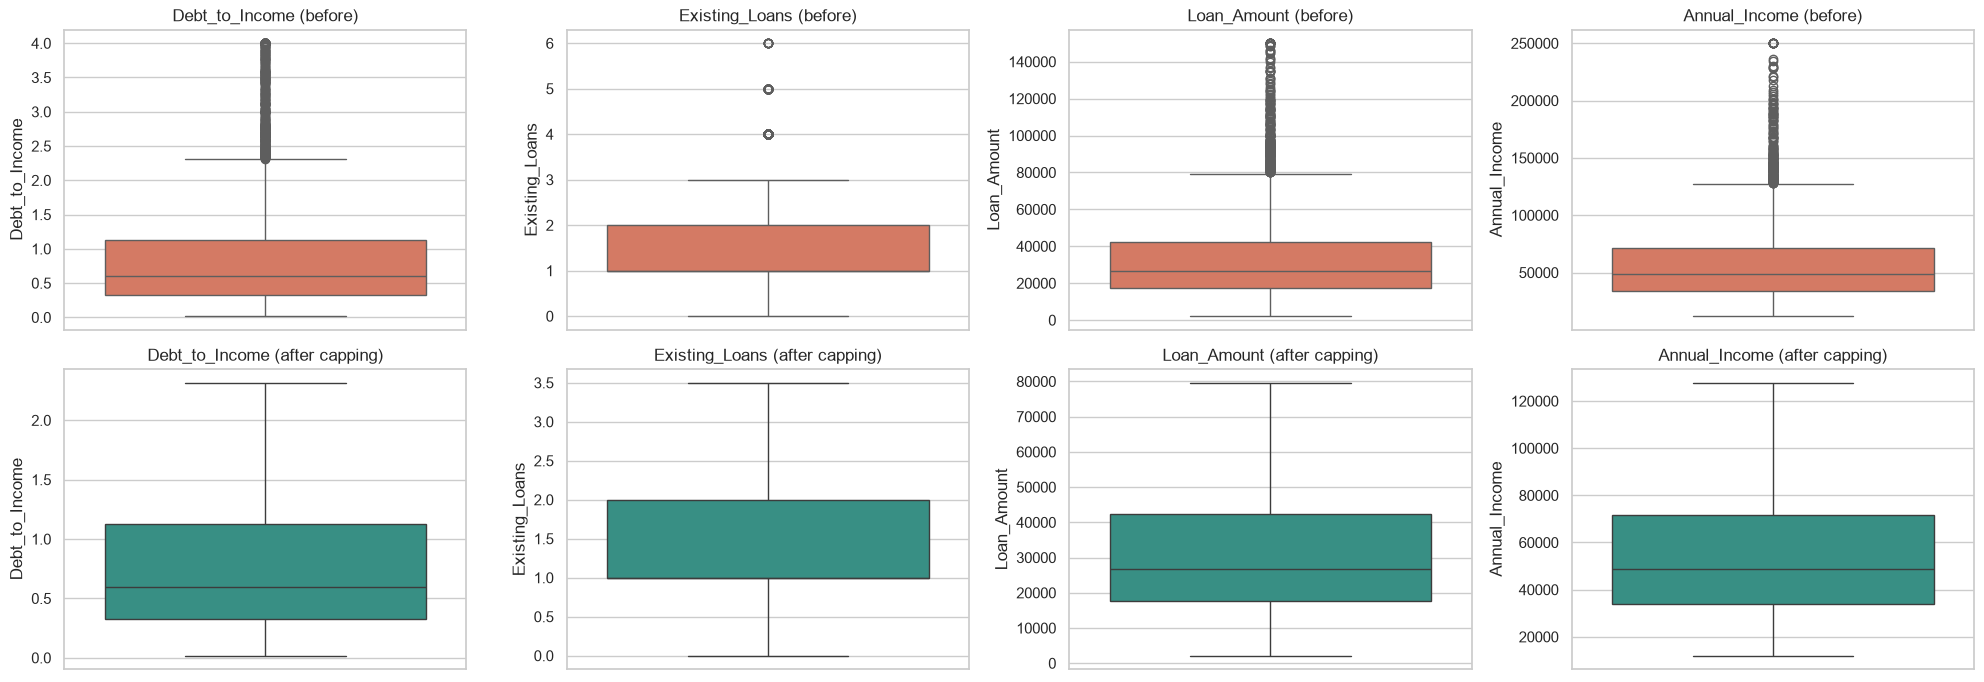

In [18]:
df_clean = df.copy()
for c in num_cols:
    lo, hi = iqr_bounds(df_clean[c])
    df_clean[c] = df_clean[c].clip(lower=lo, upper=hi)

# Before / after comparison for the most affected features
top = outlier_report.sort_values("Outliers", ascending=False).head(4)["Feature"].tolist()
fig, axes = plt.subplots(2, len(top), figsize=(5 * len(top), 7))
for i, c in enumerate(top):
    sns.boxplot(y=df[c], ax=axes[0, i], color="#e76f51"); axes[0, i].set_title(f"{c} (before)")
    sns.boxplot(y=df_clean[c], ax=axes[1, i], color="#2a9d8f"); axes[1, i].set_title(f"{c} (after capping)")
plt.tight_layout()
plt.show()

## 6. Feature Engineering

In [19]:
df_fe = df_clean.copy()

# Affordability / leverage
df_fe["Loan_to_Income"]       = df_fe["Loan_Amount"] / (df_fe["Annual_Income"] + 1)
df_fe["Income_per_Loan"]      = df_fe["Annual_Income"] / (df_fe["Existing_Loans"] + 1)
df_fe["Total_Debt_Burden"]    = df_fe["Debt_to_Income"] * df_fe["Annual_Income"]

# Payment behaviour
df_fe["Late_Payment_Rate"]    = df_fe["Late_Payments"] / (df_fe["Existing_Loans"] + 1)
df_fe["Credit_x_NoLate"]      = df_fe["Credit_Score"] * (1 / (1 + df_fe["Late_Payments"]))

# Stability
df_fe["Employment_Ratio"]     = df_fe["Years_Employed"] / (df_fe["Age"] - 17).clip(lower=1)
df_fe["Income_per_Year_Age"]  = df_fe["Annual_Income"] / df_fe["Age"]

# Binned credit-score band (ordinal 0-3)
df_fe["Credit_Band"] = pd.cut(df_fe["Credit_Score"], bins=[0, 580, 670, 740, 900],
                              labels=[0, 1, 2, 3]).astype(int)

new_feats = ["Loan_to_Income", "Income_per_Loan", "Total_Debt_Burden", "Late_Payment_Rate",
             "Credit_x_NoLate", "Employment_Ratio", "Income_per_Year_Age", "Credit_Band"]
print("New features:", new_feats)
df_fe[new_feats + ["Risk_Category"]].groupby("Risk_Category").mean().round(3)

New features: ['Loan_to_Income', 'Income_per_Loan', 'Total_Debt_Burden', 'Late_Payment_Rate', 'Credit_x_NoLate', 'Employment_Ratio', 'Income_per_Year_Age', 'Credit_Band']


,Loan_to_Income,Income_per_Loan,Total_Debt_Burden,Late_Payment_Rate,Credit_x_NoLate,Employment_Ratio,Income_per_Year_Age,Credit_Band
Risk_Category,,,,,,,,
High,1.102,22924.008,44066.375,0.657,326.952,0.601,1228.723,0.592
Low,0.524,36571.154,30401.666,0.516,465.093,0.609,1730.841,2.112
Medium,0.670,30105.268,34982.686,0.592,385.866,0.485,1463.180,1.200


## 7. Categorical Encoding

- `Education_Level` → **ordinal** (it has a natural order)
- `Employment_Type`, `Marital_Status` → **one-hot** (nominal)
- Target `Risk_Category` → **label encoded** (Low=0, Medium=1, High=2)

In [20]:
df_enc = df_fe.copy()

edu_order = {"High School": 0, "Bachelor": 1, "Master": 2, "PhD": 3}
df_enc["Education_Level"] = df_enc["Education_Level"].map(edu_order)

df_enc = pd.get_dummies(df_enc, columns=["Employment_Type", "Marital_Status"], drop_first=False, dtype=int)

le = LabelEncoder()
le.classes_ = np.array(["Low", "Medium", "High"])          # fixed, interpretable order
df_enc["Risk_Category"] = df_enc["Risk_Category"].map({"Low": 0, "Medium": 1, "High": 2})
class_names = ["Low", "Medium", "High"]

X = df_enc.drop(columns=["Risk_Category"])
y = df_enc["Risk_Category"]
feature_names = X.columns.tolist()
print("Feature matrix:", X.shape)
print("Features:", feature_names)

Feature matrix: (5000, 24)
Features: ['Age', 'Annual_Income', 'Credit_Score', 'Loan_Amount', 'Education_Level', 'Existing_Loans', 'Late_Payments', 'Debt_to_Income', 'Years_Employed', 'Loan_to_Income', 'Income_per_Loan', 'Total_Debt_Burden', 'Late_Payment_Rate', 'Credit_x_NoLate', 'Employment_Ratio', 'Income_per_Year_Age', 'Credit_Band', 'Employment_Type_Business', 'Employment_Type_Salaried', 'Employment_Type_Self-employed', 'Employment_Type_Unemployed', 'Marital_Status_Divorced', 'Marital_Status_Married', 'Marital_Status_Single']


## 8–9. Train-Test Splitting & Feature Scaling

The split is done **first**, then the scaler is fit on the **training data only** – this prevents data leakage.
The split is stratified so each risk class has the same proportion in train and test.

In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, " Test:", X_test.shape)
print("\nTrain class share:\n", y_train.value_counts(normalize=True).sort_index().round(3))
print("\nTest class share:\n", y_test.value_counts(normalize=True).sort_index().round(3))

Train: (4000, 24)  Test: (1000, 24)

Train class share:
 Risk_Category
0    0.34
1    0.34
2    0.32
Name: proportion, dtype: float64

Test class share:
 Risk_Category
0    0.34
1    0.34
2    0.32
Name: proportion, dtype: float64


In [22]:
# Scale only continuous columns; leave binary/ordinal indicator columns as they are
binary_cols = [c for c in X.columns if c.startswith(("Employment_Type_", "Marital_Status_"))]
scale_cols = [c for c in X.columns if c not in binary_cols]

scaler = StandardScaler()
X_train_s = X_train.copy()
X_test_s = X_test.copy()
X_train_s[scale_cols] = scaler.fit_transform(X_train[scale_cols])
X_test_s[scale_cols] = scaler.transform(X_test[scale_cols])

X_train_s.describe().T[["mean", "std"]].head(8).round(3)

,mean,std
Age,0.0,1.0
Annual_Income,-0.0,1.0
Credit_Score,0.0,1.0
Loan_Amount,-0.0,1.0
Education_Level,-0.0,1.0
Existing_Loans,-0.0,1.0
Late_Payments,0.0,1.0
Debt_to_Income,-0.0,1.0


## 10. Class Imbalance Analysis (SMOTE)

In [23]:
counts = y_train.value_counts().sort_index()
ratio = counts.max() / counts.min()
print(pd.DataFrame({"class": class_names, "count": counts.values, "share_%": (100 * counts.values / counts.sum()).round(2)}))
print(f"\nImbalance ratio (max/min): {ratio:.2f}")
print("→ Mild imbalance. SMOTE is still applied to the training data only, to test whether it helps.")

    class  count  share_%
0     Low   1360     34.0
1  Medium   1360     34.0
2    High   1280     32.0

Imbalance ratio (max/min): 1.06
→ Mild imbalance. SMOTE is still applied to the training data only, to test whether it helps.


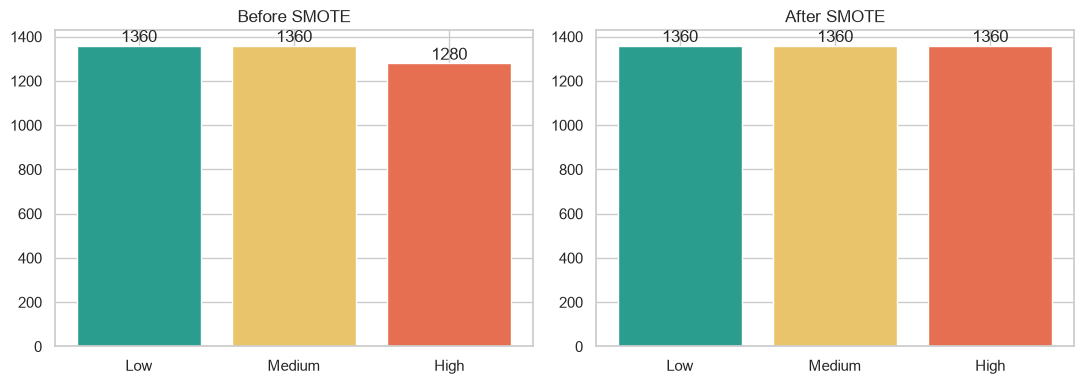

In [24]:
smote = SMOTE(random_state=RANDOM_STATE)
X_train_res, y_train_res = smote.fit_resample(X_train_s, y_train)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, yy, t in zip(axes, [y_train, y_train_res], ["Before SMOTE", "After SMOTE"]):
    vc = pd.Series(yy).value_counts().sort_index()
    ax.bar(class_names, vc.values, color=["#2a9d8f", "#e9c46a", "#e76f51"])
    ax.set_title(t)
    for i, v in enumerate(vc.values):
        ax.text(i, v, v, ha="center", va="bottom")
plt.tight_layout()
plt.show()

## 11. Model Building

Six classifiers are trained. To avoid leakage, SMOTE is wrapped **inside an `imblearn` Pipeline**, so during
cross-validation it only ever resamples the training folds – never the validation fold.

In [25]:
def make_models():
    return {
        "XGBoost": XGBClassifier(objective="multi:softprob", eval_metric="mlogloss",
                                 random_state=RANDOM_STATE, n_jobs=-1, verbosity=0),
        "CatBoost": CatBoostClassifier(loss_function="MultiClass", random_seed=RANDOM_STATE,
                                       verbose=0, thread_count=-1),
        "LightGBM": LGBMClassifier(objective="multiclass", random_state=RANDOM_STATE,
                                   n_jobs=-1, verbose=-1),
        "Random Forest": RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
        "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
        "Logistic Regression": LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    }

def as_pipe(model):
    return ImbPipeline([("smote", SMOTE(random_state=RANDOM_STATE)), ("model", model)])

models = make_models()
baseline = {}
for name, m in models.items():
    t0 = time.time()
    pipe = as_pipe(m).fit(X_train_s, y_train)
    pred = pipe.predict(X_test_s)
    baseline[name] = {"Accuracy": accuracy_score(y_test, pred),
                      "F1_macro": f1_score(y_test, pred, average="macro"),
                      "Train_sec": time.time() - t0}
baseline_df = pd.DataFrame(baseline).T.sort_values("F1_macro", ascending=False).round(4)
print("Baseline (default hyperparameters) on the test set:")
baseline_df

Baseline (default hyperparameters) on the test set:


,Accuracy,F1_macro,Train_sec
Logistic Regression,0.776,0.7784,0.1286
Gradient Boosting,0.760,0.7622,8.5269
LightGBM,0.759,0.7604,0.7477
CatBoost,0.746,0.7475,10.2294
XGBoost,0.741,0.7425,0.8787
Random Forest,0.732,0.7345,0.8899


## 12–13. Hyperparameter Tuning with Stratified K-Fold Cross-Validation

`RandomizedSearchCV` with a **5-fold `StratifiedKFold`**, scored on **macro-F1**. Randomized search keeps the
runtime manageable; raise `N_ITER` for a more exhaustive search.

In [26]:
N_ITER = 10          # increase (e.g. 30-50) for a deeper search
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

param_grids = {
    "XGBoost": {
        "model__n_estimators": [100, 200, 300, 500],
        "model__max_depth": [3, 4, 5, 6, 8],
        "model__learning_rate": [0.01, 0.03, 0.05, 0.1, 0.2],
        "model__subsample": [0.7, 0.8, 0.9, 1.0],
        "model__colsample_bytree": [0.6, 0.8, 1.0],
    },
    "CatBoost": {
        "model__iterations": [200, 400, 600],
        "model__depth": [4, 6, 8],
        "model__learning_rate": [0.03, 0.05, 0.1, 0.2],
        "model__l2_leaf_reg": [1, 3, 5, 9],
    },
    "LightGBM": {
        "model__n_estimators": [100, 200, 300, 500],
        "model__num_leaves": [15, 31, 63],
        "model__learning_rate": [0.01, 0.03, 0.05, 0.1],
        "model__subsample": [0.7, 0.8, 1.0],
        "model__colsample_bytree": [0.6, 0.8, 1.0],
        "model__min_child_samples": [10, 20, 40],
    },
    "Random Forest": {
        "model__n_estimators": [200, 300, 500],
        "model__max_depth": [None, 8, 12, 20],
        "model__min_samples_split": [2, 5, 10],
        "model__min_samples_leaf": [1, 2, 4],
        "model__max_features": ["sqrt", "log2"],
    },
    "Gradient Boosting": {
        "model__n_estimators": [100, 200, 300],
        "model__learning_rate": [0.03, 0.05, 0.1],
        "model__max_depth": [2, 3, 4, 5],
        "model__subsample": [0.7, 0.85, 1.0],
    },
    "Logistic Regression": {
        "model__C": [0.01, 0.1, 1, 10, 100],
        "model__solver": ["lbfgs", "saga"],
    },
}

tuned = {}        # name -> fitted best pipeline
search_log = {}   # name -> (best_cv_f1, best_params)

for name, model in make_models().items():
    t0 = time.time()
    n_iter = min(N_ITER, int(np.prod([len(v) for v in param_grids[name].values()])))
    rs = RandomizedSearchCV(as_pipe(model), param_grids[name], n_iter=n_iter, cv=skf,
                            scoring="f1_macro", n_jobs=1, random_state=RANDOM_STATE, refit=True)
    rs.fit(X_train_s, y_train)
    tuned[name] = rs.best_estimator_
    search_log[name] = (rs.best_score_, rs.best_params_)
    print(f"{name:20s} best CV macro-F1 = {rs.best_score_:.4f}   ({time.time()-t0:.0f}s)")

XGBoost              best CV macro-F1 = 0.7588   (110s)
CatBoost             best CV macro-F1 = 0.7610   (506s)
LightGBM             best CV macro-F1 = 0.7545   (138s)
Random Forest        best CV macro-F1 = 0.7488   (76s)
Gradient Boosting    best CV macro-F1 = 0.7581   (409s)
Logistic Regression  best CV macro-F1 = 0.7697   (43s)


In [27]:
for name, (score, params) in search_log.items():
    print(f"\n{name}  (CV macro-F1 {score:.4f})")
    for k, v in params.items():
        print(f"   {k.replace('model__', '')}: {v}")


XGBoost  (CV macro-F1 0.7588)
   subsample: 0.8
   n_estimators: 300
   max_depth: 5
   learning_rate: 0.03
   colsample_bytree: 0.6

CatBoost  (CV macro-F1 0.7610)
   learning_rate: 0.1
   l2_leaf_reg: 1
   iterations: 400
   depth: 4

LightGBM  (CV macro-F1 0.7545)
   subsample: 0.7
   num_leaves: 15
   n_estimators: 100
   min_child_samples: 40
   learning_rate: 0.03
   colsample_bytree: 1.0

Random Forest  (CV macro-F1 0.7488)
   n_estimators: 200
   min_samples_split: 5
   min_samples_leaf: 2
   max_features: log2
   max_depth: 20

Gradient Boosting  (CV macro-F1 0.7581)
   subsample: 1.0
   n_estimators: 200
   max_depth: 2
   learning_rate: 0.1

Logistic Regression  (CV macro-F1 0.7697)
   solver: lbfgs
   C: 1


In [28]:
# Full 5-fold stratified CV on the tuned models, with several metrics at once
scoring = {"accuracy": "accuracy", "precision": "precision_macro",
           "recall": "recall_macro", "f1": "f1_macro"}
cv_rows = []
for name, pipe in tuned.items():
    res = cross_validate(pipe, X_train_s, y_train, cv=skf, scoring=scoring, n_jobs=1)
    cv_rows.append({"Model": name,
                    **{f"CV_{k}": res[f"test_{k}"].mean() for k in scoring},
                    "CV_f1_std": res["test_f1"].std()})
cv_df = pd.DataFrame(cv_rows).set_index("Model").sort_values("CV_f1", ascending=False).round(4)
cv_df

,CV_accuracy,CV_precision,CV_recall,CV_f1,CV_f1_std
Model,,,,,
Logistic Regression,0.7678,0.7716,0.7684,0.7697,0.0131
CatBoost,0.7588,0.7635,0.7596,0.7610,0.0191
XGBoost,0.7565,0.7612,0.7573,0.7588,0.0175
Gradient Boosting,0.7558,0.7606,0.7566,0.7581,0.0102
LightGBM,0.7530,0.7557,0.7539,0.7545,0.0108
Random Forest,0.7463,0.7513,0.7471,0.7488,0.0146


## 14. Model Evaluation (Accuracy, Precision, Recall, F1-score)

In [29]:
eval_rows, preds, probas = [], {}, {}
for name, pipe in tuned.items():
    p = pipe.predict(X_test_s)
    preds[name] = p
    probas[name] = pipe.predict_proba(X_test_s)
    eval_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, p),
        "Precision": precision_score(y_test, p, average="macro"),
        "Recall": recall_score(y_test, p, average="macro"),
        "F1": f1_score(y_test, p, average="macro"),
    })
eval_df = pd.DataFrame(eval_rows).set_index("Model")
eval_df["ROC_AUC"] = [roc_auc_score(y_test, probas[m], multi_class="ovr", average="macro") for m in eval_df.index]
eval_df = eval_df.sort_values("F1", ascending=False).round(4)
eval_df

,Accuracy,Precision,Recall,F1,ROC_AUC
Model,,,,,
Logistic Regression,0.776,0.7812,0.7765,0.7784,0.9203
CatBoost,0.770,0.7727,0.7707,0.7715,0.9091
XGBoost,0.754,0.7579,0.7543,0.7554,0.9074
Gradient Boosting,0.751,0.7575,0.7514,0.7537,0.9052
LightGBM,0.752,0.7554,0.7525,0.7535,0.9010
Random Forest,0.735,0.7389,0.7357,0.7370,0.8966


In [30]:
best_name_preview = eval_df.index[0]
print(f"Per-class report – {best_name_preview}\n")
print(classification_report(y_test, preds[best_name_preview], target_names=class_names, digits=3))

Per-class report – Logistic Regression

              precision    recall  f1-score   support

         Low      0.821     0.824     0.822       340
      Medium      0.666     0.703     0.684       340
        High      0.857     0.803     0.829       320

    accuracy                          0.776      1000
   macro avg      0.781     0.777     0.778      1000
weighted avg      0.780     0.776     0.777      1000



## 15. Confusion Matrix & ROC-AUC

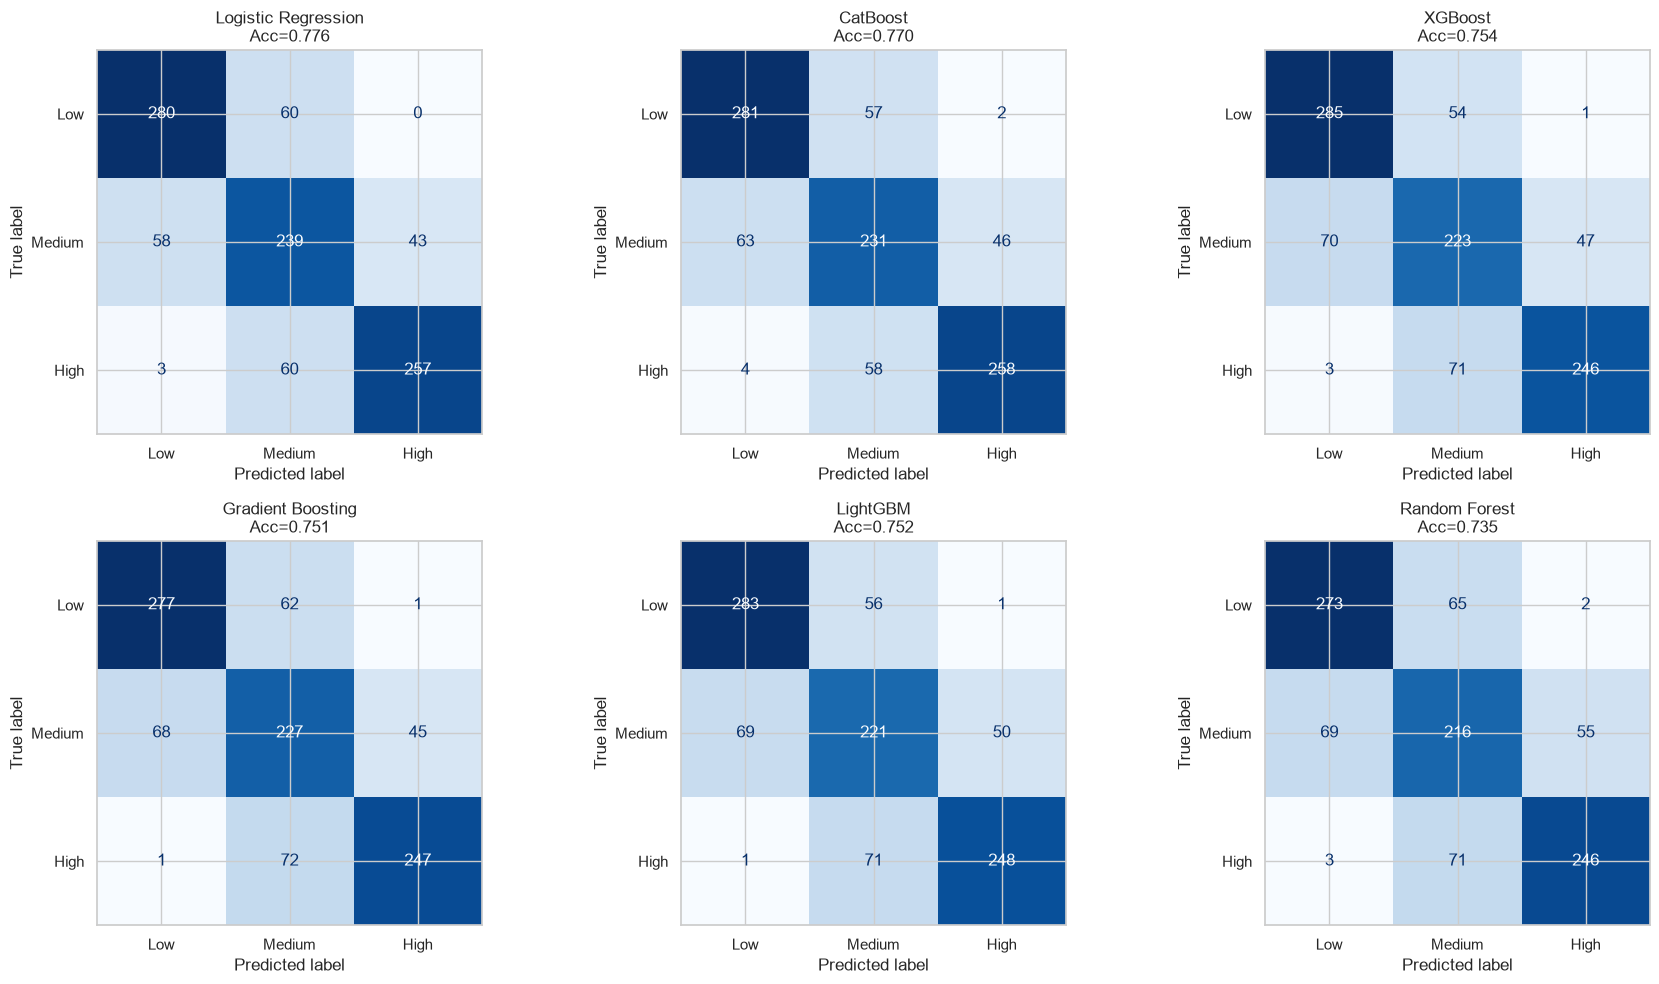

In [31]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, name in zip(axes.ravel(), eval_df.index):
    cm = confusion_matrix(y_test, preds[name])
    ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{name}\nAcc={eval_df.loc[name, 'Accuracy']:.3f}")
plt.tight_layout()
plt.show()

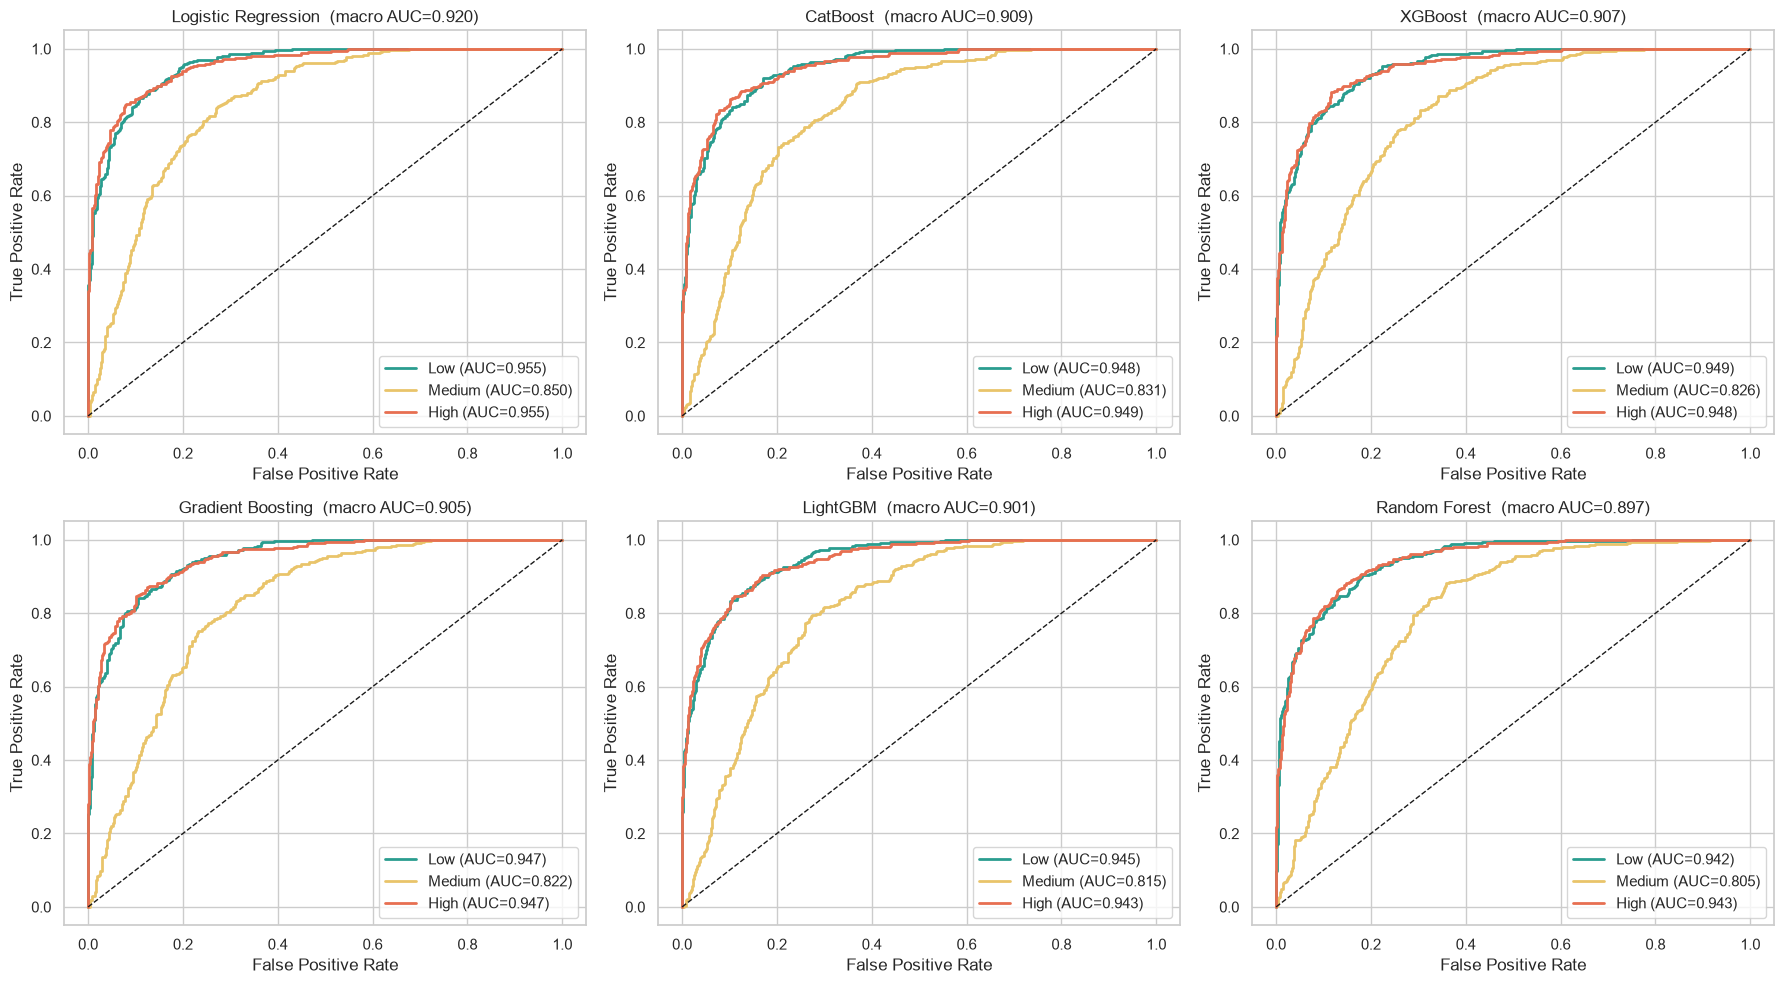

In [32]:
# One-vs-Rest ROC curves for every model
y_test_bin = label_binarize(y_test, classes=[0, 1, 2])
colors = ["#2a9d8f", "#e9c46a", "#e76f51"]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, name in zip(axes.ravel(), eval_df.index):
    for i, cls in enumerate(class_names):
        fpr, tpr, _ = roc_curve(y_test_bin[:, i], probas[name][:, i])
        ax.plot(fpr, tpr, color=colors[i], lw=2, label=f"{cls} (AUC={auc(fpr, tpr):.3f})")
    ax.plot([0, 1], [0, 1], "k--", lw=1)
    ax.set_title(f"{name}  (macro AUC={eval_df.loc[name, 'ROC_AUC']:.3f})")
    ax.set_xlabel("False Positive Rate"); ax.set_ylabel("True Positive Rate")
    ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 17. Model Comparison

,Accuracy,Precision,Recall,F1,ROC_AUC,CV_f1,CV_f1_std,Baseline_F1,Tuning_Gain
Model,,,,,,,,,
Logistic Regression,0.776,0.7812,0.7765,0.7784,0.9203,0.7697,0.0131,0.7784,0.0000
CatBoost,0.770,0.7727,0.7707,0.7715,0.9091,0.7610,0.0191,0.7475,0.0240
XGBoost,0.754,0.7579,0.7543,0.7554,0.9074,0.7588,0.0175,0.7425,0.0129
Gradient Boosting,0.751,0.7575,0.7514,0.7537,0.9052,0.7581,0.0102,0.7622,-0.0085
LightGBM,0.752,0.7554,0.7525,0.7535,0.9010,0.7545,0.0108,0.7604,-0.0069
Random Forest,0.735,0.7389,0.7357,0.7370,0.8966,0.7488,0.0146,0.7345,0.0025


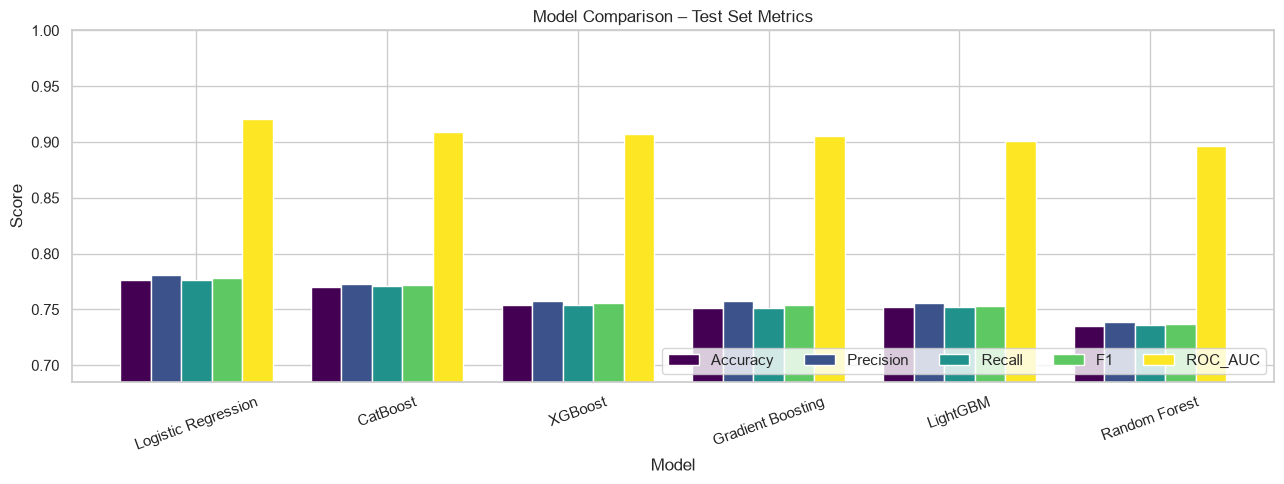

In [33]:
compare = eval_df.join(cv_df[["CV_f1", "CV_f1_std"]])
compare["Baseline_F1"] = baseline_df["F1_macro"]
compare["Tuning_Gain"] = compare["F1"] - compare["Baseline_F1"]
compare = compare.round(4)
display(compare)

ax = compare[["Accuracy", "Precision", "Recall", "F1", "ROC_AUC"]].plot(
    kind="bar", figsize=(13, 5), width=0.8, colormap="viridis")
ax.set_title("Model Comparison – Test Set Metrics")
ax.set_ylabel("Score")
lo = compare[["Accuracy", "Precision", "Recall", "F1"]].min().min()
ax.set_ylim(max(0, lo - 0.05), 1.0)
plt.xticks(rotation=20)
plt.legend(loc="lower right", ncol=5)
plt.tight_layout()
plt.show()

## 18. Best Model Selection

The best model is chosen by **cross-validated macro-F1** (more reliable than a single test split), with the
test-set F1 shown alongside as the final hold-out check.

In [34]:
best_name = compare["CV_f1"].idxmax()
best_pipe = tuned[best_name]
print(f"BEST MODEL: {best_name}")
print(f"  CV macro-F1   : {compare.loc[best_name, 'CV_f1']:.4f} (± {compare.loc[best_name, 'CV_f1_std']:.4f})")
print(f"  Test Accuracy : {compare.loc[best_name, 'Accuracy']:.4f}")
print(f"  Test Macro-F1 : {compare.loc[best_name, 'F1']:.4f}")
print(f"  Test ROC-AUC  : {compare.loc[best_name, 'ROC_AUC']:.4f}")
print("\nTop-ranked models by test F1:", compare.sort_values('F1', ascending=False).index.tolist()[:3])

BEST MODEL: Logistic Regression
  CV macro-F1   : 0.7697 (± 0.0131)
  Test Accuracy : 0.7760
  Test Macro-F1 : 0.7784
  Test ROC-AUC  : 0.9203

Top-ranked models by test F1: ['Logistic Regression', 'CatBoost', 'XGBoost']


## 16. Feature Importance & SHAP Analysis

SHAP is computed on the best **tree-based** model (fast exact TreeExplainer). If the overall best model is
Logistic Regression, the top tree model is used for SHAP and its coefficients are plotted separately.

SHAP model: CatBoost


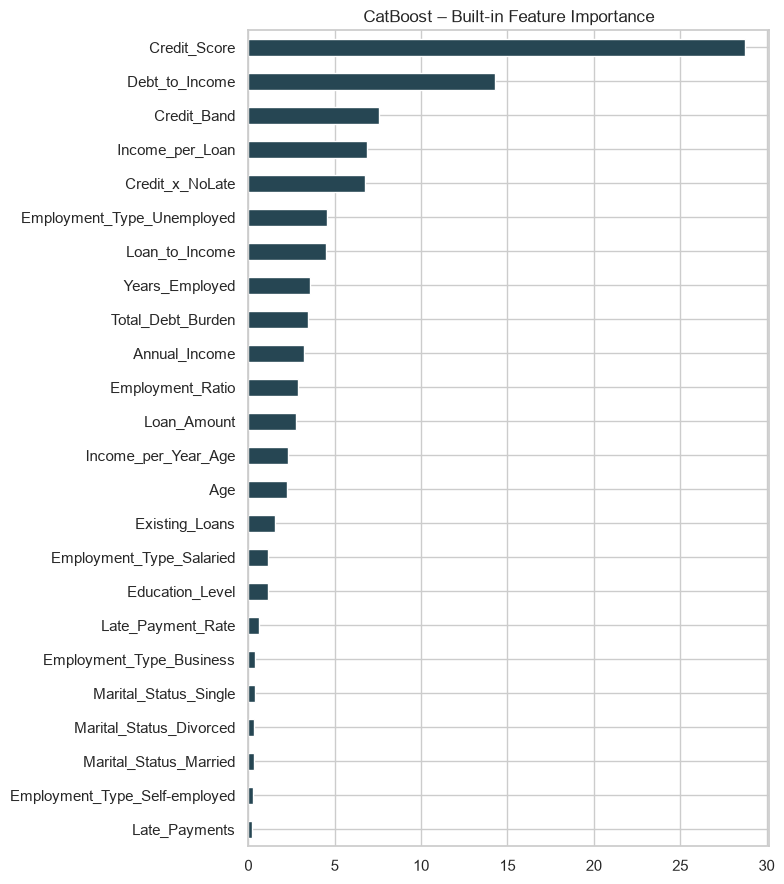

In [35]:
tree_names = ["XGBoost", "CatBoost", "LightGBM", "Random Forest", "Gradient Boosting"]
shap_name = best_name if best_name in tree_names else compare.loc[tree_names, "CV_f1"].idxmax()
shap_model = tuned[shap_name].named_steps["model"]
print("SHAP model:", shap_name)

# Built-in feature importance
if hasattr(shap_model, "feature_importances_"):
    imp = pd.Series(shap_model.feature_importances_, index=feature_names).sort_values()
    plt.figure(figsize=(8, 9))
    imp.plot(kind="barh", color="#264653")
    plt.title(f"{shap_name} – Built-in Feature Importance")
    plt.tight_layout()
    plt.show()

Classes explained: 3 | shape per class: (800, 24)


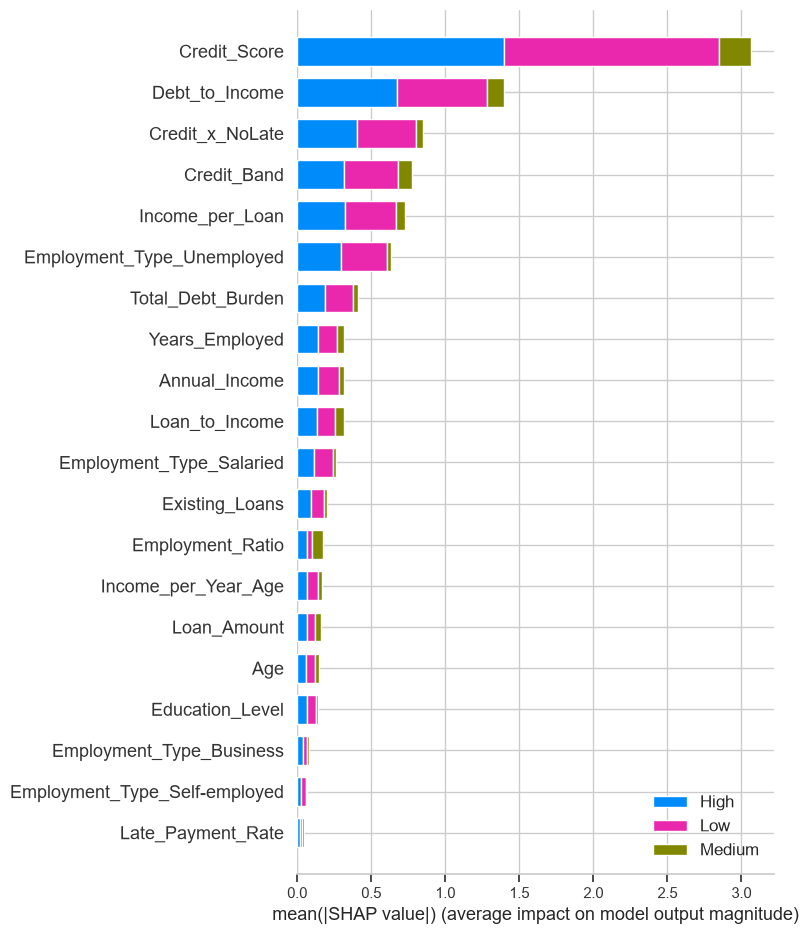

In [36]:
# SHAP values on a test sample
X_shap = X_test_s.sample(n=min(800, len(X_test_s)), random_state=RANDOM_STATE)
explainer = shap.TreeExplainer(shap_model)
sv = explainer.shap_values(X_shap)

# Normalise to a list of (n_samples, n_features) arrays – one per class
if isinstance(sv, np.ndarray) and sv.ndim == 3:
    sv = [sv[:, :, i] for i in range(sv.shape[2])]
print("Classes explained:", len(sv), "| shape per class:", sv[0].shape)

shap.summary_plot(sv, X_shap, class_names=class_names, plot_type="bar", show=True)

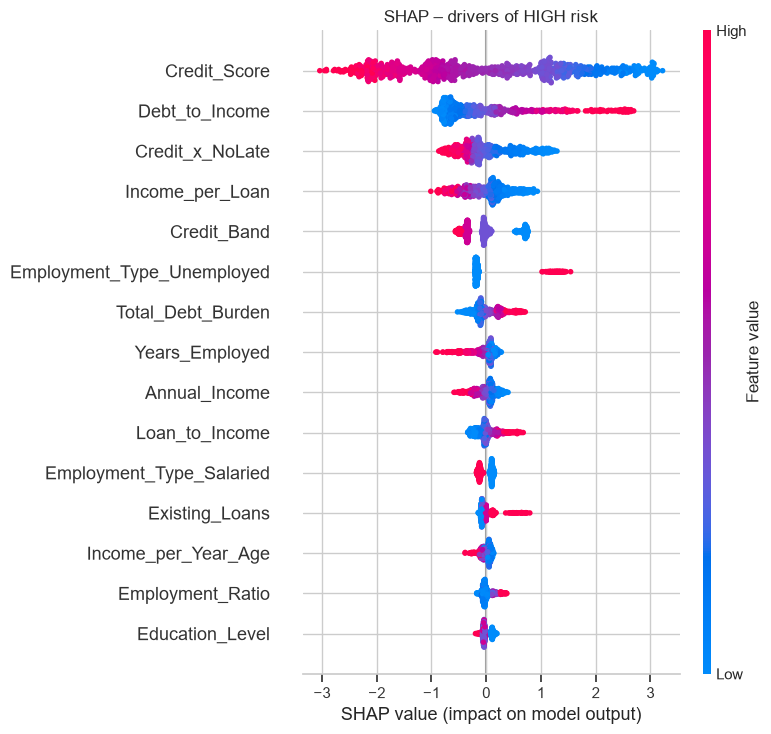

In [37]:
# Beeswarm for the HIGH-risk class: how each feature value pushes a customer toward High risk
high_idx = class_names.index("High")
shap.summary_plot(sv[high_idx], X_shap, show=False, max_display=15)
plt.title("SHAP – drivers of HIGH risk")
plt.tight_layout()
plt.show()

In [38]:
# Ranked mean |SHAP| across all classes
mean_abs = np.mean([np.abs(s).mean(axis=0) for s in sv], axis=0)
shap_rank = pd.Series(mean_abs, index=feature_names).sort_values(ascending=False)
print("Top 10 features by mean |SHAP|:")
print(shap_rank.head(10).round(4))

Top 10 features by mean |SHAP|:
Credit_Score                  1.0222
Debt_to_Income                0.4657
Credit_x_NoLate               0.2841
Credit_Band                   0.2593
Income_per_Loan               0.2435
Employment_Type_Unemployed    0.2112
Total_Debt_Burden             0.1360
Years_Employed                0.1065
Annual_Income                 0.1062
Loan_to_Income                0.1060
dtype: float64


In [39]:
# Logistic Regression coefficients (interpretable baseline)
lr_model = tuned["Logistic Regression"].named_steps["model"]
coef = pd.DataFrame(lr_model.coef_.T, index=feature_names, columns=class_names)
coef["abs_max"] = coef.abs().max(axis=1)
coef.sort_values("abs_max", ascending=False).drop(columns="abs_max").head(12).round(3)

,Low,Medium,High
Credit_Score,3.124,-0.082,-3.042
Employment_Type_Unemployed,-1.636,0.831,0.805
Employment_Type_Business,0.846,0.689,-1.535
Employment_Type_Salaried,0.932,0.599,-1.530
Debt_to_Income,-1.316,-0.017,1.333
Employment_Type_Self-employed,0.407,0.676,-1.083
Marital_Status_Married,0.047,0.775,-0.822
Marital_Status_Single,-0.014,0.789,-0.775
Marital_Status_Divorced,0.117,0.620,-0.737
Late_Payments,-0.667,0.078,0.589


## 19. Export Model (`.pkl`)

The pickle stores everything required for inference: the fitted pipeline, the scaler, the column order, the
label mapping and the encoding rules – so new raw data can be scored consistently.

In [40]:
artifact = {
    "model_name": best_name,
    "model": best_pipe,                    # imblearn pipeline (SMOTE is skipped automatically at predict time)
    "scaler": scaler,
    "scale_cols": scale_cols,
    "feature_names": feature_names,
    "class_names": class_names,
    "education_order": edu_order,
    "metrics": compare.loc[best_name].to_dict(),
}
with open("best_risk_model.pkl", "wb") as f:
    pickle.dump(artifact, f)
print("Saved → best_risk_model.pkl")

Saved → best_risk_model.pkl


In [41]:
# Reload and verify that the exported model reproduces the same predictions
with open("best_risk_model.pkl", "rb") as f:
    loaded = pickle.load(f)

reload_pred = loaded["model"].predict(X_test_s)
assert (reload_pred == preds[best_name]).all(), "Reloaded model predictions differ!"
print("Round-trip check passed ✔  | accuracy:", round(accuracy_score(y_test, reload_pred), 4))

Round-trip check passed ✔  | accuracy: 0.776


In [42]:
# Example: score a brand-new raw customer record with the exported artifact
def predict_risk(raw: dict, art=loaded):
    r = pd.DataFrame([raw])
    # same feature engineering as training
    r["Loan_to_Income"]      = r["Loan_Amount"] / (r["Annual_Income"] + 1)
    r["Income_per_Loan"]     = r["Annual_Income"] / (r["Existing_Loans"] + 1)
    r["Total_Debt_Burden"]   = r["Debt_to_Income"] * r["Annual_Income"]
    r["Late_Payment_Rate"]   = r["Late_Payments"] / (r["Existing_Loans"] + 1)
    r["Credit_x_NoLate"]     = r["Credit_Score"] * (1 / (1 + r["Late_Payments"]))
    r["Employment_Ratio"]    = r["Years_Employed"] / (r["Age"] - 17).clip(lower=1)
    r["Income_per_Year_Age"] = r["Annual_Income"] / r["Age"]
    r["Credit_Band"]         = pd.cut(r["Credit_Score"], bins=[0, 580, 670, 740, 900], labels=[0, 1, 2, 3]).astype(int)
    r["Education_Level"]     = r["Education_Level"].map(art["education_order"])
    r = pd.get_dummies(r, columns=["Employment_Type", "Marital_Status"], dtype=int)
    r = r.reindex(columns=art["feature_names"], fill_value=0)
    r[art["scale_cols"]] = art["scaler"].transform(r[art["scale_cols"]])
    proba = art["model"].predict_proba(r)[0]
    return art["class_names"][int(np.argmax(proba))], dict(zip(art["class_names"], proba.round(3)))

sample = {"Age": 35, "Annual_Income": 45000, "Credit_Score": 590, "Loan_Amount": 60000,
          "Employment_Type": "Self-employed", "Education_Level": "Bachelor", "Marital_Status": "Single",
          "Existing_Loans": 3, "Late_Payments": 4, "Debt_to_Income": 1.6, "Years_Employed": 2.0}
predict_risk(sample)

('High',
 {'Low': np.float64(0.0),
  'Medium': np.float64(0.007),
  'High': np.float64(0.993)})